##**UCUCI Bank: Loan Portfolio Health & Repayment Performance Analysis 🏦**
####**Objective:**


UCUCI Bank is one of India's largest private sector banks, offering a wide range of retail lending products including personal loans, credit card loans, and debt consolidation financing.

As its loan book has grown significantly over the past decade, the bank's leadership has identified a critical need to better understand the health of its loan portfolio — specifically, which borrowers are most likely to repay on time, and which segments are driving delinquency and default risk.

With increasing competitive pressure from digital lending platforms and tightening regulatory expectations around provisioning for bad loans, the bank's Risk Analytics team has been tasked with a deep-dive into borrower behaviour and loan performance data.







####**Need for analysis:**
The analysis will have a significant business impact, it will help the bank identify patterns in repayment outcomes and surface actionable insights that will help the bank improve its overall Loan Repayment Rate while optimising interest rate and grade-based risk pricing.
As a data analyst at UCUCI Bank, mission is to explore the dataset and uncover insights that help improve the Loan Repayment Rate (LRR).


###**Dataset overview:**


*   **Dataset name-** UCUCI_Dataset
*   **Number of rows-** 887379
*   **Number of columns-** 57

*  **Description-** The dataset captures the key metrics for UCUCI bank, providing insights into borrower financial profile, repayment history and current status.
###**Data Column Definition-**


1.   **id-** Unique loan identifier assigned to each loan.
2.   **member_id-** Unique borrower identifier.
3. **loan_amnt-** Total loan amount applied for by the borrower (INR equivalent).
4. **funded_amnt-** Actual amount funded/approved for the loan.
5. **funded_amnt_inv-** Amount funded by investors through the platform.
6. **term-** Repayment duration of the loan.
7. **int_rate-**  Annual interest rate charged on the loan (%).
8. **installment-** Fixed monthly payment amount due from the borrower.
9. **grade-** Overall loan risk grade assigned by the platform (A–G).
10. **sub_grade-** More granular risk tier within the grade.
11. **emp_title-** Borrower's current job title.
12. **emp_length-** Number of years the borrower has been employed.
13. **home_ownership-** Borrower's home ownership status.
14. **annual_inc-** Borrower's self-reported annual income.
15. **verification_status-** Whether the borrower's income was verified.
16. **issue_d-** Month and year the loan was issued.
17. **loan_status-** Current status of the loan.
18. **pymnt_plan-** Whether the borrower is on a payment plan.
19. **purpose-** Stated purpose for taking the loan.
20. **title-** Borrower-provided title/description of the loan purpose.
21. **zip_code-** First 3 digits of the borrower's zip code.
22. **addr_state-** US state (or equivalent region) of the borrower's address.
23. **dti-** Debt-to-income ratio: monthly debt obligations ÷ monthly income.
24. **delinq_2yrs-** Number of times the borrower was 30+ days delinquent in the past 2 years.
25. **earliest_cr_line-** Date of the borrower's earliest reported credit line.
26. **inq_last_6mths-** Number of credit inquiries in the last 6 months.
27. **mths_since_last_delinq-** Months since last delinquency event (null if never delinquent).
28. **mths_since_last_record-** Months since last public derogatory record.
29. **open_acc-** Number of open credit lines in the borrower's credit file.
30. **pub_rec-** Number of derogatory public records on the borrower's credit file.
31. **revol_bal-** Total revolving balance currently owed across credit lines.
32. **revol_util-** Revolving credit utilisation rate (%).
33. **total_acc-** Total number of credit lines ever opened by the borrower.
34. **initial_list_status-** Initial listing status of the loan on the platform.







###**Data Loading and Dataframe Generation**

####Importing required python packages to load, prepare and analyse given datasets:



#Install gdown:

In [1]:
!pip install gdown

#Import Libraries:




In [2]:
import gdown
import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations
import matplotlib.pyplot as plt  # For plotting and visualization
import seaborn as sns  # For advanced visualizations

#Set File Id and create download URL:

In [3]:
# Google Drive file ID
file_id = "1BS8azi6nWEXm0Zvo3nD7t3sWaZWt1Ny8"
# Construct the file's download URL
url = f"https://drive.google.com/uc?id={file_id}"
# set output file name
output_file = "UCUCI_dataset.csv"


#Download file:

In [4]:
gdown.download(url, output_file, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1BS8azi6nWEXm0Zvo3nD7t3sWaZWt1Ny8
From (redirected): https://drive.google.com/uc?id=1BS8azi6nWEXm0Zvo3nD7t3sWaZWt1Ny8&confirm=t&uuid=916ba285-7081-4a86-86fc-0b21ac30c548
To: /content/UCUCI_dataset.csv
100%|██████████| 411M/411M [00:03<00:00, 134MB/s]


'UCUCI_dataset.csv'

# Load the CSV file into a Pandas DataFrame:

In [5]:
data = pd.read_csv(output_file)

/tmp/ipykernel_2033/154153668.py:1: DtypeWarning: Columns (19,55) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(output_file)


#Viewing first 5 rows

In [6]:
data.head(5)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,...,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,...,NaN,Sep-2013,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,...,NaN,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0
3,1076863,1277178,10000.0,10000.0,10000.0,36 months,13.49,339.31,C,C1,...,NaN,Jan-2015,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0
4,1075358,1311748,3000.0,3000.0,3000.0,60 months,12.69,67.79,B,B5,...,Feb-2016,Jan-2016,0.0,NaN,1.0,INDIVIDUAL,NaN,NaN,NaN,0.0


#Checking shape of dataset

In [7]:
data.shape

(887379, 57)

887379 rows and 57 columns.

#Dataset information

In [8]:
#column names
data.columns

Index(['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv',
       'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title',
       'emp_length', 'home_ownership', 'annual_inc', 'verification_status',
       'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose',
       'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs',
       'earliest_cr_line', 'inq_last_6mths', 'mths_since_last_delinq',
       'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'out_prncp',
       'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp',
       'total_rec_int', 'total_rec_late_fee', 'recoveries',
       'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt',
       'next_pymnt_d', 'last_credit_pull_d', 'collections_12_mths_ex_med',
       'mths_since_last_major_derog', 'policy_code', 'application_type',
       'annual_inc_joint', 'dti_joint', 'verification_status_joint',
    

In [9]:
#data types
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 887379 entries, 0 to 887378
Data columns (total 57 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           887379 non-null  int64  
 1   member_id                    887379 non-null  int64  
 2   loan_amnt                    887379 non-null  float64
 3   funded_amnt                  887379 non-null  float64
 4   funded_amnt_inv              887379 non-null  float64
 5   term                         887379 non-null  object 
 6   int_rate                     887379 non-null  float64
 7   installment                  887379 non-null  float64
 8   grade                        887379 non-null  object 
 9   sub_grade                    887379 non-null  object 
 10  emp_title                    835917 non-null  object 
 11  emp_length                   842554 non-null  object 
 12  home_ownership               887379 non-null  object 
 13 

#Statistical summary

In [10]:
round(data.describe(),2)

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,int_rate,installment,annual_inc,dti,delinq_2yrs,...,total_rec_late_fee,recoveries,collection_recovery_fee,last_pymnt_amnt,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,annual_inc_joint,dti_joint,acc_now_delinq
count,887379.00,887379.00,887379.00,887379.00,887379.00,887379.00,887379.00,887375.00,887379.00,887350.00,...,887379.00,887379.00,887379.00,887379.00,887234.00,221703.00,887379.0,511.00,509.00,887350.00
mean,32465133.06,35001824.82,14755.26,14741.88,14702.46,13.25,436.72,75027.59,18.16,0.31,...,0.40,45.92,4.88,2164.15,0.01,44.10,1.0,109981.01,18.31,0.00
std,22827341.72,24113354.68,8435.46,8429.90,8442.11,4.38,244.19,64698.30,17.19,0.86,...,4.09,409.69,63.13,4794.78,0.13,22.18,0.0,52730.38,7.17,0.08
min,54734.00,70473.00,500.00,500.00,0.00,5.32,15.67,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,1.0,17950.00,3.00,0.00
25%,9206643.00,10877133.50,8000.00,8000.00,8000.00,9.99,260.70,45000.00,11.91,0.00,...,0.00,0.00,0.00,280.17,0.00,27.00,1.0,76032.50,13.20,0.00
50%,34433267.00,37095283.00,13000.00,13000.00,13000.00,12.99,382.55,65000.00,17.65,0.00,...,0.00,0.00,0.00,462.78,0.00,44.00,1.0,101771.00,17.61,0.00
75%,54908135.00,58471347.00,20000.00,20000.00,20000.00,16.20,572.60,90000.00,23.95,0.00,...,0.00,0.00,0.00,831.24,0.00,61.00,1.0,132800.00,22.65,0.00
max,68617057.00,73544841.00,35000.00,35000.00,35000.00,28.99,1445.46,9500000.00,9999.00,39.00,...,358.68,33520.27,7002.19,36475.59,20.00,188.00,1.0,500000.00,43.86,14.00


#Categorical summary

In [11]:
data.describe(include='object')

,term,grade,sub_grade,emp_title,emp_length,home_ownership,verification_status,issue_d,loan_status,pymnt_plan,...,title,zip_code,addr_state,earliest_cr_line,initial_list_status,last_pymnt_d,next_pymnt_d,last_credit_pull_d,application_type,verification_status_joint
count,887379,887379,887379,835917,842554,887379,887379,887379,887379,887379,...,887226,887379,887379,887350,887379,869720,634408,887326,887379,511
unique,2,7,35,299271,11,6,3,103,10,2,...,63143,935,51,697,2,98,100,103,2,3
top,36 months,B,B3,Teacher,10+ years,MORTGAGE,Source Verified,Oct-2015,Current,n,...,Debt consolidation,945xx,CA,Aug-2001,f,Jan-2016,Feb-2016,Jan-2016,INDIVIDUAL,Not Verified
freq,621125,254535,56323,13469,291569,443557,329558,48631,601779,887369,...,414001,9770,129517,6659,456848,470150,553406,730574,886868,283


#Data cleaning

Checking for duplicated values:

In [12]:

duplicate_count = data.duplicated().sum()
print(f"Number of Duplicate Rows in the Dataset: {duplicate_count}")

Number of Duplicate Rows in the Dataset: 0


Checking for missing values:

In [13]:
missing_table=pd.DataFrame({
    "Missing Values":data.isnull().sum(),
    "Percentage":round(data.isnull().mean()*100,2)
})

missing_table.sort_values("Percentage",ascending=False)

,Missing Values,Percentage
annual_inc_joint,886868,99.94
dti_joint,886870,99.94
verification_status_joint,886868,99.94
desc,761353,85.80
mths_since_last_record,750326,84.56
mths_since_last_major_derog,665676,75.02
mths_since_last_delinq,454312,51.20
next_pymnt_d,252971,28.51
emp_title,51462,5.80
emp_length,44825,5.05


Dropping columns that are not required:

In [14]:
columns_to_drop = [
    "annual_inc_joint",
    "dti_joint",
    "verification_status_joint",
    "desc"
]

data.drop(columns=columns_to_drop, inplace=True)

The dataset contained several variables with a high proportion of missing values. Columns related to joint loan applications (annual_inc_joint, dti_joint, and verification_status_joint) were removed because more than 99% of their values were missing, indicating that joint loans represented only a very small fraction of the dataset. The desc column was also removed due to its high missingness (85.80%) and limited relevance to the project objectives.

Handle mths_since_last_record:

In [15]:
data["mths_since_last_record"] = data["mths_since_last_record"].fillna(-1)

Handle mths_since_last_major_derog:

In [16]:
data["mths_since_last_major_derog"] = data["mths_since_last_major_derog"].fillna(-1)

mths_since_last_record and mths_since_last_major_derog were retained. Their missing values were replaced with -1, as the absence of a value indicates that the borrower has no recorded public derogatory record or major derogatory event. Preserving these variables maintains valuable credit history information for subsequent analysis.

In [17]:
data.isnull().sum().sort_values(ascending=False)

,0
mths_since_last_delinq,454312
next_pymnt_d,252971
emp_title,51462
emp_length,44825
last_pymnt_d,17659
revol_util,502
title,153
collections_12_mths_ex_med,145
last_credit_pull_d,53
delinq_2yrs,29


Handle mths_since_last_delinq:

In [18]:
data["mths_since_last_delinq"] = data["mths_since_last_delinq"].fillna(-1)

Handle emp_title:

In [19]:
data["emp_title"] = data["emp_title"].fillna("Unknown")

Handle emp_length:

In [20]:
data["emp_length"] = data["emp_length"].fillna(data["emp_length"].mode()[0])

Revolving Utilization:

In [21]:
data["revol_util"] = data["revol_util"].fillna(data["revol_util"].median())

Annual income:

In [22]:
data["annual_inc"] = data["annual_inc"].fillna(data["annual_inc"].median())

Loan title:

In [23]:
data["title"] = data["title"].fillna(data["purpose"])

Drop irrelevant columns:


In [24]:
data.drop(columns=["last_pymnt_d"], inplace=True)

In [25]:
data.drop(columns=["collections_12_mths_ex_med"], inplace=True)

In [26]:
data.drop(columns=["last_credit_pull_d"], inplace=True)

Convert date time columns:

In [27]:
date_columns = [
    "issue_d",
    "earliest_cr_line"]

for col in date_columns:
    data[col] = pd.to_datetime(
    data[col],
    format="%b-%Y",
    errors="coerce"
)

Final check:

In [28]:
missing = pd.DataFrame({
    "Missing Values": data.isnull().sum(),
    "Percentage": round(data.isnull().mean()*100, 2)
})

missing[missing["Missing Values"] > 0].sort_values("Percentage", ascending=False)

,Missing Values,Percentage
next_pymnt_d,252971,28.51
delinq_2yrs,29,0.00
inq_last_6mths,29,0.00
earliest_cr_line,29,0.00
open_acc,29,0.00
pub_rec,29,0.00
total_acc,29,0.00
acc_now_delinq,29,0.00


Drop rows with missing values:

In [29]:
data = data.dropna(subset=[
    "delinq_2yrs",
    "earliest_cr_line",
    "inq_last_6mths",
    "open_acc",
    "pub_rec",
    "total_acc",
    "acc_now_delinq"
])

Verifying:

In [30]:
data.isnull().sum().sort_values(ascending=False)

,0
next_pymnt_d,252971
id,0
loan_amnt,0
funded_amnt,0
funded_amnt_inv,0
term,0
int_rate,0
installment,0
grade,0
sub_grade,0


The remaining missing values were limited to 29 observations (less than 0.01% of the dataset) across several credit history variables. Since these represented an extremely small proportion of the overall dataset, the corresponding records were removed to preserve data quality while avoiding unnecessary imputation.

#Check unique values:

In [31]:
data.nunique()

,0
id,887350
member_id,887350
loan_amnt,1372
funded_amnt,1372
funded_amnt_inv,9856
term,2
int_rate,542
installment,68704
grade,7
sub_grade,35


Final check data type:

In [32]:
data.dtypes

,0
id,int64
member_id,int64
loan_amnt,float64
funded_amnt,float64
funded_amnt_inv,float64
term,object
int_rate,float64
installment,float64
grade,object
sub_grade,object


#KPIs
This section calculates the primary business metrics used to evaluate the health of the loan portfolio. These KPIs provide an overview of lending performance, repayment efficiency, default risk, and recovery effectiveness.

**KPI 1 – Total Number of Loans**

In [33]:
total_loans = len(data)

print("Total Loans Issued:", total_loans)

Total Loans Issued: 887350


This KPI represents the total number of loans included in the portfolio and provides the overall scale of lending operations.

**KPI 2 – Total Funded Amount**

In [34]:
total_funded = data["funded_amnt"].sum()

print("Total Funded Amount: ${:,.2f}".format(total_funded))

Total Funded Amount: $13,081,521,550.00


Total funded amount represents the total capital disbursed by the bank across all loans.

**KPI 3 – Total Amount Repaid**

In [35]:
total_repaid = data["total_pymnt"].sum()

print("Total Amount Repaid: ${:,.2f}".format(total_repaid))

Total Amount Repaid: $6,707,419,764.24


This includes both principal and interest repaid by borrowers.

**KPI 4 – Loan Repayment Rate (LRR)**

This is the primary KPI.





In [36]:
LRR = (total_repaid / total_funded) * 100

print("Loan Repayment Rate (LRR): {:.2f}%".format(LRR))

Loan Repayment Rate (LRR): 51.27%


LRR measures the proportion of funded loan principal and interest that has been successfully recovered from borrowers. Improving LRR directly reduces credit losses, strengthens provisioning efficiency, and supports sustainable portfolio growth.

**KPI 5 - Completed Loan LRR**

In [37]:
completed_loans = data[data["loan_status"].isin(["Fully Paid", "Charged Off"])]

completed_lrr = (
    completed_loans["total_pymnt"].sum() /
    completed_loans["funded_amnt"].sum()
) * 100

print(f"Completed Loan LRR: {completed_lrr:.2f}%")

Completed Loan LRR: 100.65%


The overall Loan Repayment Rate (LRR) across the portfolio is lower because a large proportion of loans are still in the Current status and have not yet completed repayment. When only completed loans (Fully Paid and Charged Off) are considered, the LRR is 100.65%, indicating that the bank has recovered the full principal along with interest, despite losses from charged-off loans.

**KPI 6 – Default Rate**

In [38]:
charged_off = data[data["loan_status"] == "Charged Off"]

default_rate = (
    len(charged_off) /
    len(data)
) * 100

print("Default Rate: {:.2f}%".format(default_rate))

Default Rate: 5.10%


**KPI 7 – Fully Paid Rate**

In [39]:
fully_paid = data[data["loan_status"] == "Fully Paid"]

fully_paid_rate = (
    len(fully_paid) /
    len(data)
) * 100

print("Fully Paid Rate: {:.2f}%".format(fully_paid_rate))

Fully Paid Rate: 23.41%


**KPI 8 – Current Loan Rate**

In [40]:
current_loans = data[data["loan_status"] == "Current"]

current_rate = (
    len(current_loans) /
    len(data)
) * 100

print("Current Loan Rate: {:.2f}%".format(current_rate))

Current Loan Rate: 67.82%


Not all loans are completed. Current loans are still active and should not be classified as successful or defaulted.

**KPI 9 – Average Interest Rate**




In [41]:
avg_interest = data["int_rate"].mean()

print("Average Interest Rate: {:.2f}%".format(avg_interest))

Average Interest Rate: 13.25%


**KPI 10 – Average Annual Income**





In [42]:
avg_income = data["annual_inc"].mean()

print("Average Annual Income: ${:,.2f}".format(avg_income))

Average Annual Income: $75,027.70


**KPI 11 – Average Debt-to-Income Ratio**

In [43]:
avg_dti = data["dti"].mean()

print("Average Debt-to-Income Ratio:", round(avg_dti,2))

Average Debt-to-Income Ratio: 18.16


**KPI 12 – Recovery Rate**

In [44]:
charged = data[data["loan_status"] == "Charged Off"]

recovery_rate = (
    charged["recoveries"].sum() /
    charged["funded_amnt"].sum()
) * 100

print("Recovery Rate: {:.2f}%".format(recovery_rate))

Recovery Rate: 6.14%


**KPI Summary Table**

In [45]:
kpi = pd.DataFrame({
    "Metric": [
        "Total Loans",
        "Total Funded Amount",
        "Total Amount Repaid",
        "Overall Loan Repayment Rate (%)",
        "Completed Loan Repayment Rate (%)",
        "Default Rate (%)",
        "Fully Paid Rate (%)",
        "Current Loan Rate (%)",
        "Average Interest Rate (%)",
        "Average Annual Income",
        "Average Debt-to-Income Ratio"
    ],

    "Value": [
        f"{total_loans:,}",
        f"${total_funded:,.2f}",
        f"${total_repaid:,.2f}",
        f"{LRR:.2f}%",
        f"{completed_lrr:.2f}%",
        f"{default_rate:.2f}%",
        f"{fully_paid_rate:.2f}%",
        f"{current_rate:.2f}%",
        f"{avg_interest:.2f}%",
        f"${avg_income:,.2f}",
        f"{avg_dti:.2f}"
    ]
})

kpi

,Metric,Value
0,Total Loans,"887,350"
1,Total Funded Amount,"$13,081,521,550.00"
2,Total Amount Repaid,"$6,707,419,764.24"
3,Overall Loan Repayment Rate (%),51.27%
4,Completed Loan Repayment Rate (%),100.65%
5,Default Rate (%),5.10%
6,Fully Paid Rate (%),23.41%
7,Current Loan Rate (%),67.82%
8,Average Interest Rate (%),13.25%
9,Average Annual Income,"$75,027.70"


### KPI Summary

The table below presents the key performance indicators used to evaluate the health of the loan portfolio.

- **Overall Loan Repayment Rate (LRR)** measures repayments across the entire portfolio, including active loans.
- **Completed Loan Repayment Rate (LRR)** considers only loans with a final outcome (Fully Paid or Charged Off), providing a clearer measure of repayment efficiency.
- The remaining KPIs summarize portfolio quality, borrower characteristics, and lending performance, forming the basis for the subsequent exploratory data analysis.

#Exploratory Data Analysis (EDA)


The objective of this section is to understand borrower behaviour, loan characteristics, and repayment performance through visualizations and statistical summaries.

Each analysis is driven by a business question and hypothesis, followed by observations and actionable insights.

###Loan Status Distribution
**Hypothesis 1-**
Most loans are currently active (Current), followed by Fully Paid loans, while Charged Off loans constitute the smallest proportion of the portfolio.

In [46]:
loan_status = (
    data["loan_status"]
    .value_counts()
    .reset_index()
)

loan_status.columns = ["Loan Status", "Count"]

loan_status

,Loan Status,Count
0,Current,601779
1,Fully Paid,207723
2,Charged Off,45248
3,Late (31-120 days),11591
4,Issued,8460
5,In Grace Period,6253
6,Late (16-30 days),2357
7,Does not meet the credit policy. Status:Fully ...,1962
8,Default,1219
9,Does not meet the credit policy. Status:Charge...,758


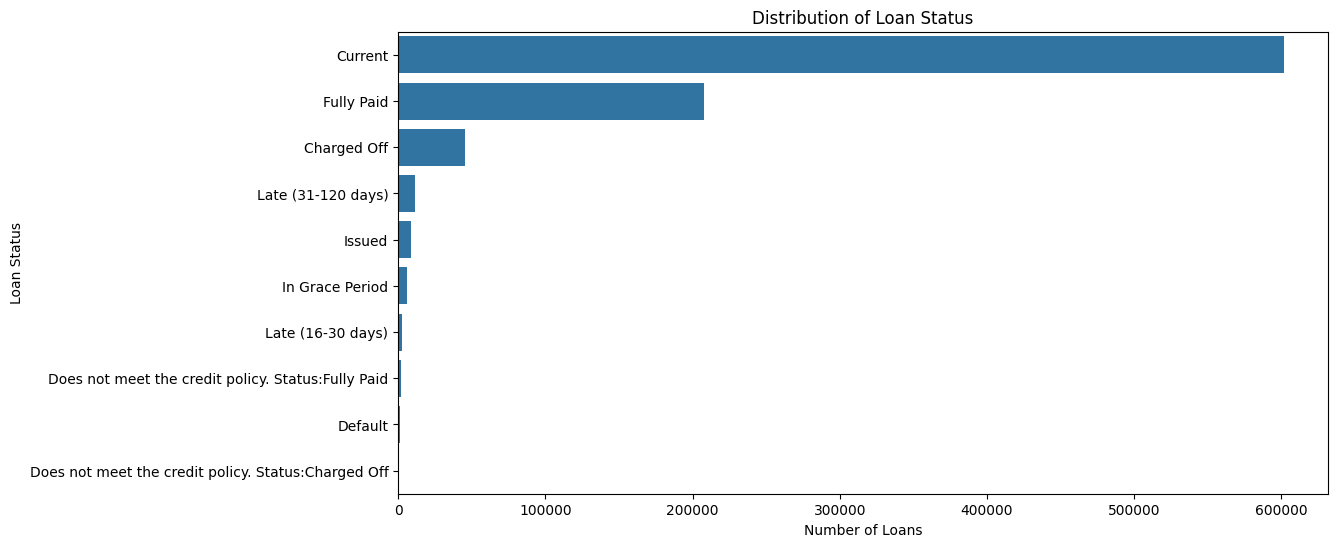

In [47]:
plt.figure(figsize=(12,6))

order = data["loan_status"].value_counts().index

sns.countplot(
    data=data,
    y="loan_status",
    order=order
)

plt.title("Distribution of Loan Status")
plt.xlabel("Number of Loans")
plt.ylabel("Loan Status")

plt.show()

Since nearly two-thirds of loans are still active, the Overall LRR is naturally lower than the Completed Loan LRR. Portfolio performance should therefore be assessed using both metrics.

###Loan Grade Distribution

 **Hypothesis 2-** Most loans belong to Grade B and Grade C.

In [48]:
grade_dist = (
    data["grade"]
    .value_counts()
    .sort_index()
    .reset_index()
)

grade_dist.columns = ["Grade", "Loans"]

grade_dist

,Grade,Loans
0,A,148191
1,B,254525
2,C,245854
3,D,139541
4,E,70704
5,F,23046
6,G,5489


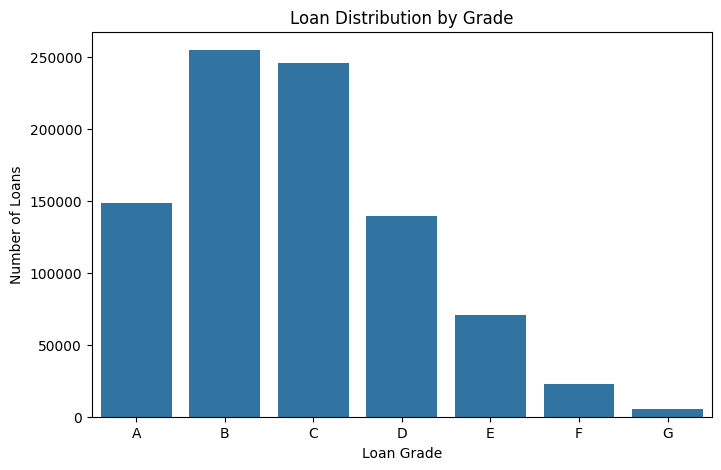

In [49]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=grade_dist,
    x="Grade",
    y="Loans"
)

plt.title("Loan Distribution by Grade")

plt.xlabel("Loan Grade")

plt.ylabel("Number of Loans")

plt.show()

A concentration of loans in higher grades indicates a conservative lending strategy, whereas a larger share of lower grades suggests higher portfolio risk.

###Default Rate by Grade
 **Hypothesis 3-** Default rates increase progressively from Grade A to Grade G.

**Create default, fully paid and current flag**

In [50]:
data["default_flag"] = data["loan_status"].apply(
    lambda x: 1 if x == "Charged Off" else 0
)

In [51]:
data["default_flag"].value_counts()

,count
default_flag,
0,842102
1,45248


In [52]:
data["fully_paid_flag"] = data["loan_status"].apply(
    lambda x: 1 if x == "Fully Paid" else 0
)

In [53]:
data["current_flag"] = data["loan_status"].apply(
    lambda x: 1 if x == "Current" else 0
)

In [54]:
grade_default = (
    data.groupby("grade")["default_flag"]
      .mean()
      .mul(100)
      .reset_index()
)

grade_default.columns = ["Grade", "Default Rate (%)"]

grade_default

,Grade,Default Rate (%)
0,A,1.765964
1,B,3.739908
2,C,5.142076
3,D,7.514637
4,E,8.850984
5,F,12.731060
6,G,14.428858


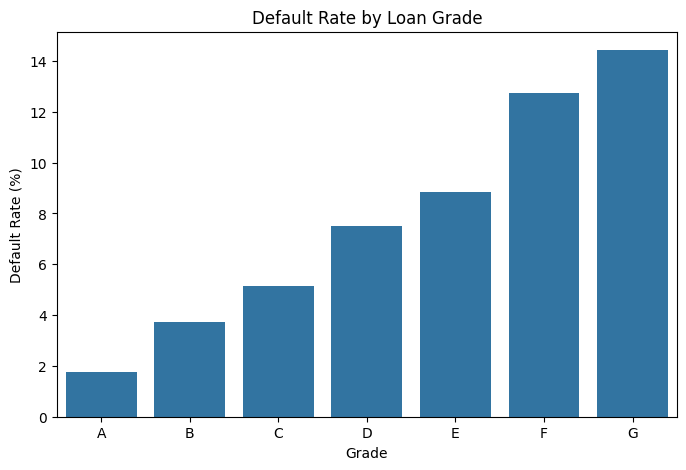

In [55]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=grade_default,
    x="Grade",
    y="Default Rate (%)"
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Grade")
plt.ylabel("Default Rate (%)")

plt.show()

Loan grade is one of the strongest predictors of repayment behaviour. Lower-grade borrowers exhibit higher default rates and should be subject to stricter underwriting or higher risk-based pricing.

###Average Interest Rate by Grade

**Hypothesis 4-** Average interest rates increase as loan grade declines.

In [56]:
interest_grade = (
    data.groupby("grade")["int_rate"]
      .mean()
      .reset_index()
)

interest_grade.columns = ["Grade", "Average Interest Rate"]

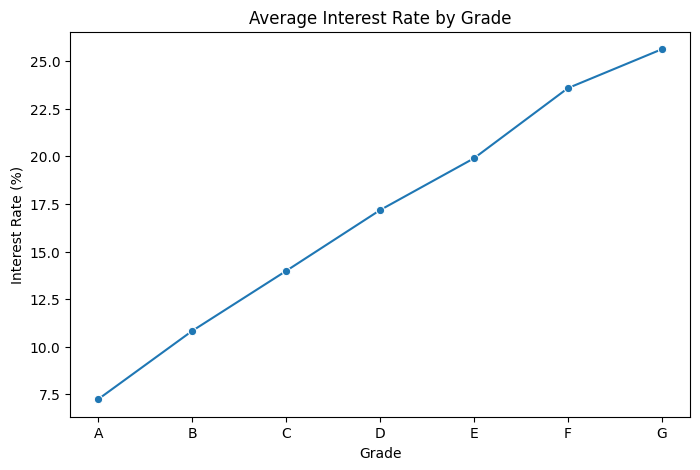

In [57]:
plt.figure(figsize=(8,5))

sns.lineplot(
    data=interest_grade,
    x="Grade",
    y="Average Interest Rate",
    marker="o"
)

plt.title("Average Interest Rate by Grade")

plt.ylabel("Interest Rate (%)")

plt.show()

The bank appears to price loans according to credit risk, indicating an effective risk-based pricing strategy.

###Sub-Grade Analysis

**Hypothesis H5-** Mid-level sub-grades contain the highest number of borrowers.

In [58]:
sub_grade = (
    data["sub_grade"]
      .value_counts()
      .sort_index()
      .reset_index()
)

sub_grade.columns = ["Sub Grade", "Loans"]

sub_grade.head()

,Sub Grade,Loans
0,A1,22912
1,A2,22482
2,A3,23453
3,A4,34530
4,A5,44814


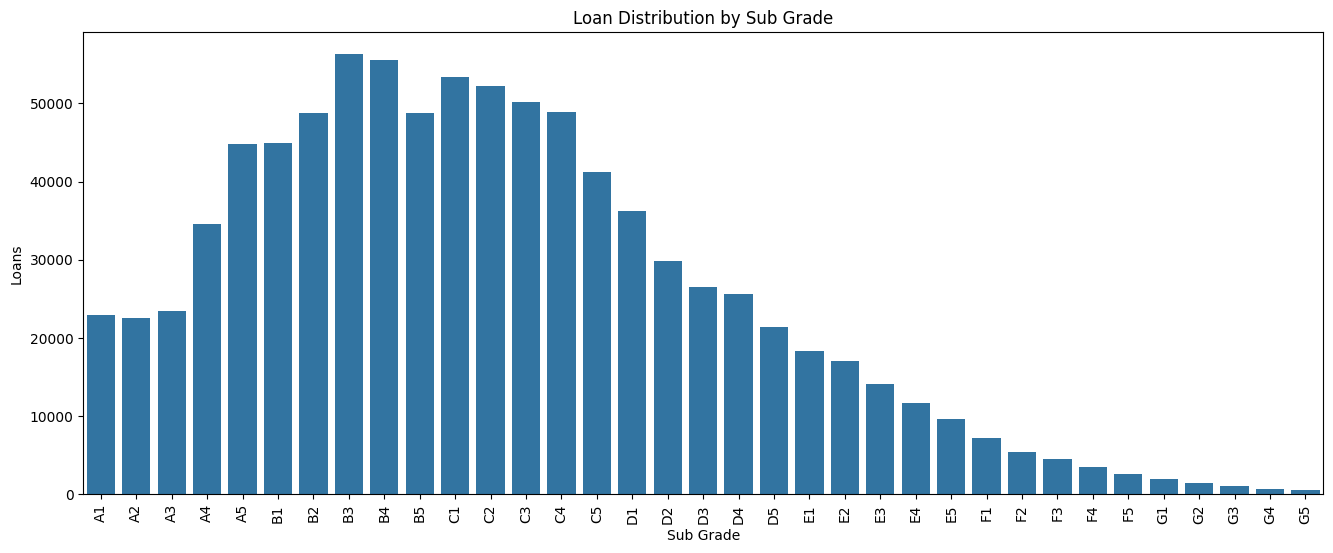

In [59]:
plt.figure(figsize=(16,6))

sns.barplot(
    data=sub_grade,
    x="Sub Grade",
    y="Loans"
)

plt.xticks(rotation=90)

plt.title("Loan Distribution by Sub Grade")

plt.show()

Sub-grade provides a more granular view of credit quality than grade and can improve lending decisions.

###Average Interest Rate by Sub-Grade

In [60]:
sub_interest = (
    data.groupby("sub_grade")["int_rate"]
      .mean()
      .reset_index()
)

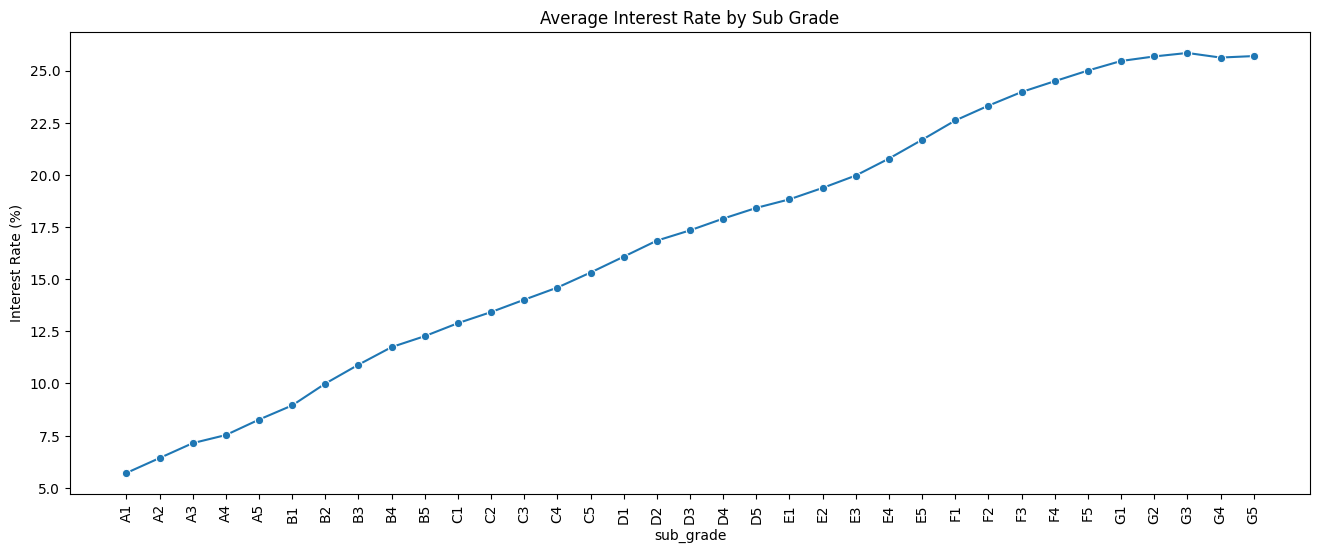

In [61]:
plt.figure(figsize=(16,6))

sns.lineplot(
    data=sub_interest,
    x="sub_grade",
    y="int_rate",
    marker="o"
)

plt.xticks(rotation=90)

plt.title("Average Interest Rate by Sub Grade")

plt.ylabel("Interest Rate (%)")

plt.show()

Sub-grade pricing should increase smoothly. Any irregularities may indicate inconsistencies in risk-based pricing.

###Loan Term Distribution

**Hypothesis H6-** Most borrowers prefer 36-month loans.

In [62]:
term_dist = (
    data["term"]
      .value_counts()
      .reset_index()
)

term_dist.columns = ["Loan Term", "Loans"]

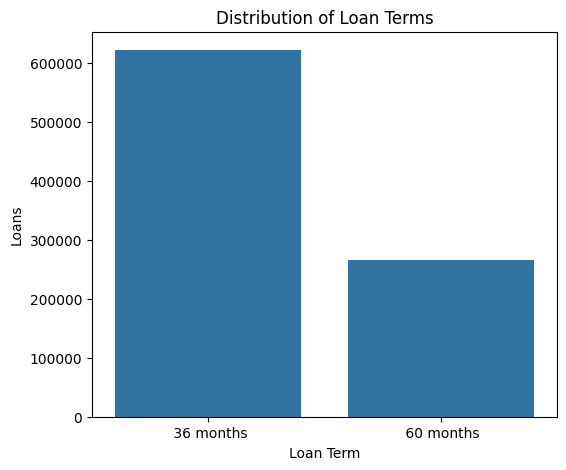

In [63]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=term_dist,
    x="Loan Term",
    y="Loans"
)

plt.title("Distribution of Loan Terms")

plt.show()

Shorter loan terms reduce credit exposure and generally improve repayment outcomes.

###Default Rate by Loan Term

**Hypothesis H7-** 60-month loans have higher default rates than 36-month loans.

In [64]:
term_default = (
    data.groupby("term")["default_flag"]
      .mean()
      .mul(100)
      .reset_index()
)

term_default.columns = ["Loan Term", "Default Rate (%)"]

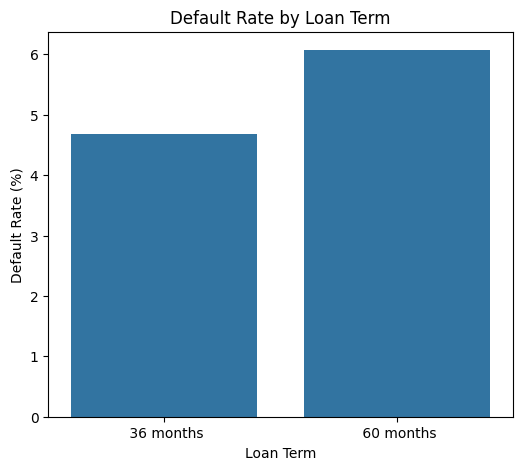

In [65]:
plt.figure(figsize=(6,5))

sns.barplot(
    data=term_default,
    x="Loan Term",
    y="Default Rate (%)"
)

plt.title("Default Rate by Loan Term")

plt.show()

60-month loans show substantially higher defaults, the bank should reassess underwriting standards or pricing for long-term lending.

#Borrower Profile Analysis
###Annual Income Distribution
**Hypothesis H8-** Most borrowers belong to the middle-income segment.

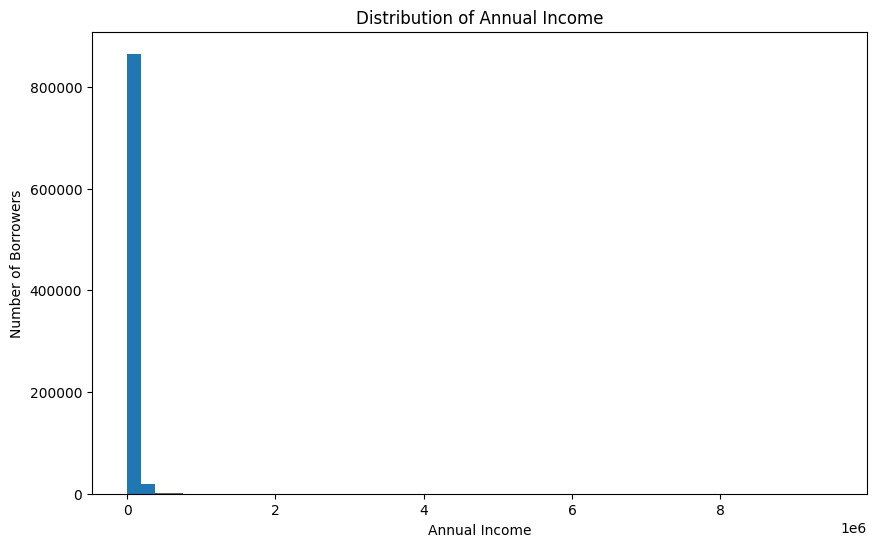

In [66]:
plt.figure(figsize=(10,6))

plt.hist(data["annual_inc"], bins=50)

plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Borrowers")

plt.show()

Most borrowers earn between lower and middle income ranges, while a small number of borrowers report exceptionally high incomes.

###Default Rate by Annual Income Quartile
**Hypothesis H9-** Higher-income borrowers have lower default rates.

In [67]:
data["income_group"] = pd.qcut(
    data["annual_inc"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

In [68]:
income_default = (
    data.groupby("income_group", observed=False)["default_flag"]
      .mean()
      .mul(100)
      .reset_index()
)

income_default

,income_group,default_flag
0,Low,6.763343
1,Medium,5.522142
2,High,4.538115
3,Very High,3.403983


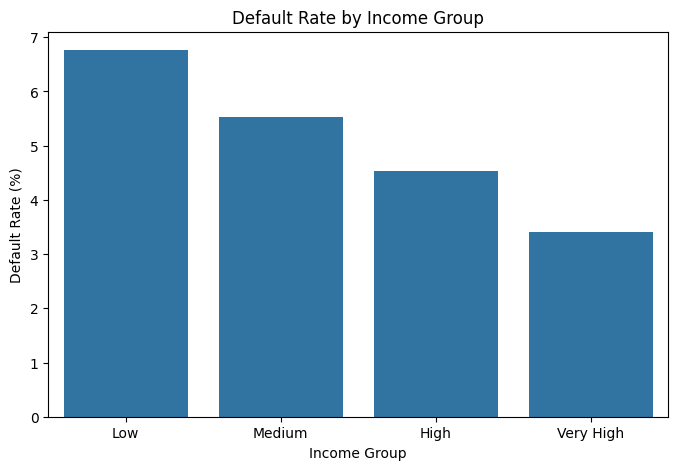

In [69]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=income_default,
    x="income_group",
    y="default_flag"
)

plt.title("Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")

plt.show()

hypothesis is supported, annual income should be given significant weight in credit assessment models.

###DTI Distribution

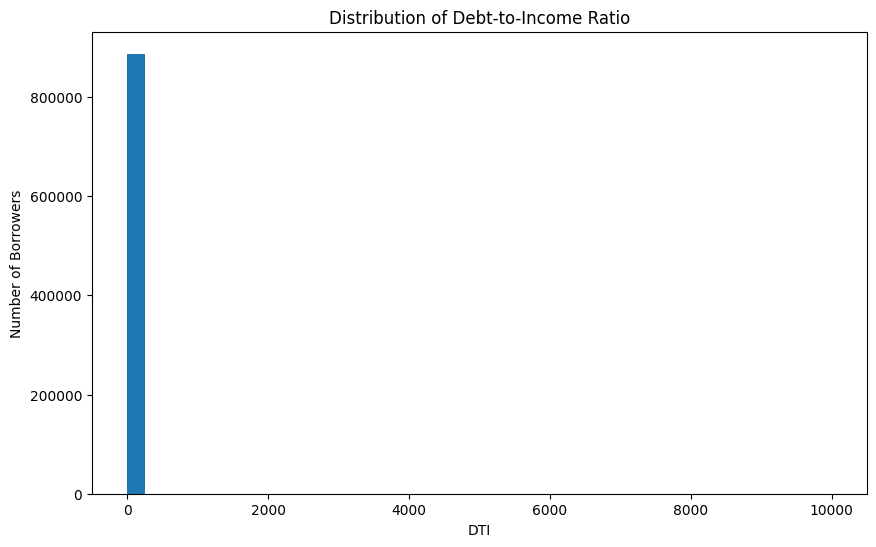

In [70]:
plt.figure(figsize=(10,6))

plt.hist(data["dti"], bins=40)

plt.title("Distribution of Debt-to-Income Ratio")
plt.xlabel("DTI")
plt.ylabel("Number of Borrowers")

plt.show()

Most borrowers have moderate DTI values, with fewer borrowers at very high DTI levels.
Borrowers with high DTI may face greater repayment pressure.

###Default Rate by DTI Group
**Hypothesis H10-** Higher DTI leads to higher default rates.



In [71]:
#create dti group
data["dti_group"] = pd.cut(
    data["dti"],
    bins=[0,10,20,30,40,100],
    labels=[
        "0-10",
        "10-20",
        "20-30",
        "30-40",
        "40+"
    ]
)

In [72]:
#calculate default rate
dti_default = (
    data.groupby("dti_group", observed=False)["default_flag"]
      .mean()
      .mul(100)
      .reset_index()
)

dti_default

,dti_group,default_flag
0,0-10,4.527172
1,10-20,5.019462
2,20-30,5.756459
3,30-40,4.344870
4,40+,0.000000


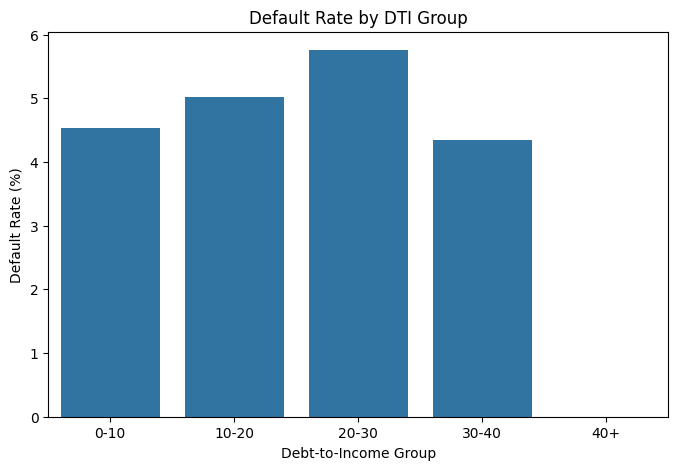

In [73]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=dti_default,
    x="dti_group",
    y="default_flag"
)

plt.title("Default Rate by DTI Group")
plt.xlabel("Debt-to-Income Group")
plt.ylabel("Default Rate (%)")

plt.show()

Borrowers with high debt obligations relative to income may require stricter eligibility criteria.

###Verification Status Distribution

In [74]:
verification = (
    data["verification_status"]
      .value_counts()
      .reset_index()
)

verification.columns = ["Verification Status", "Loans"]

verification

,Verification Status,Loans
0,Source Verified,329558
1,Verified,291071
2,Not Verified,266721


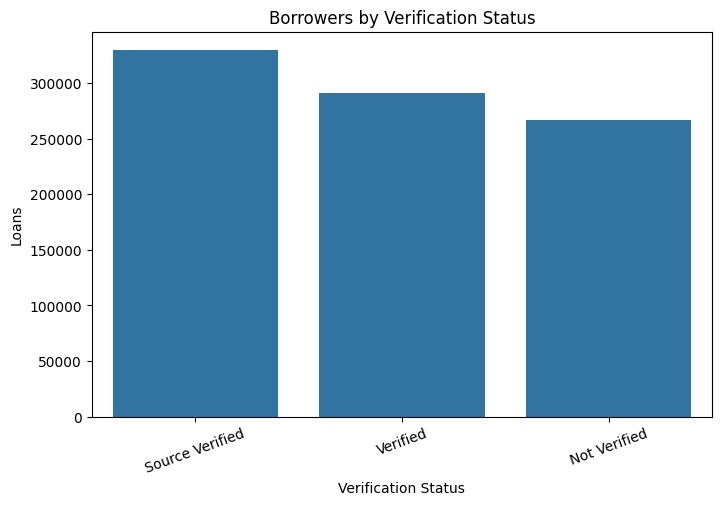

In [75]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=verification,
    x="Verification Status",
    y="Loans"
)

plt.title("Borrowers by Verification Status")

plt.xticks(rotation=20)

plt.show()

This shows the proportion of borrowers whose income has been verified before loan approval.

###Default Rate by Verification Status
**Hypothesis H11-** Verified borrowers have lower default rates than non-verified borrowers.

In [76]:
verification_default = (
    data.groupby("verification_status")["default_flag"]
      .mean()
      .mul(100)
      .reset_index()
)

verification_default.columns = [
    "Verification Status",
    "Default Rate (%)"
]

verification_default

,Verification Status,Default Rate (%)
0,Not Verified,4.577067
1,Source Verified,4.169221
2,Verified,6.630685


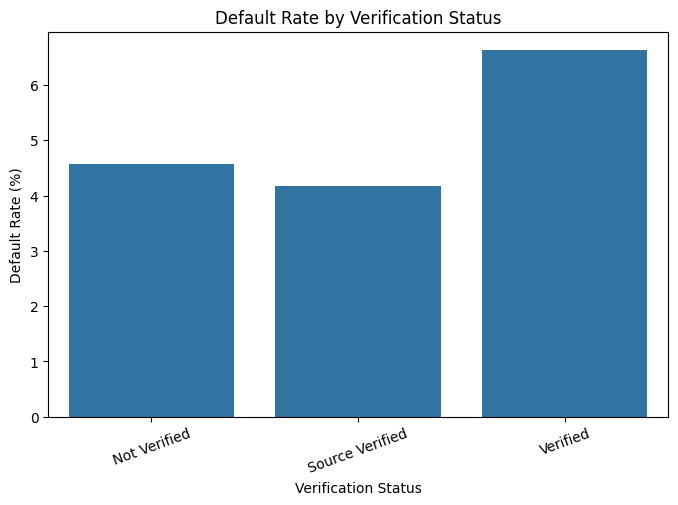

In [77]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=verification_default,
    x="Verification Status",
    y="Default Rate (%)"
)

plt.title("Default Rate by Verification Status")

plt.xticks(rotation=20)

plt.show()

If verified borrowers default less often, strengthening income verification policies could improve loan quality, but we can see that is not the case.

###Employment Length Distribution

In [78]:
#Clean Employment Length
emp_order = [
    "< 1 year",
    "1 year",
    "2 years",
    "3 years",
    "4 years",
    "5 years",
    "6 years",
    "7 years",
    "8 years",
    "9 years",
    "10+ years"
]

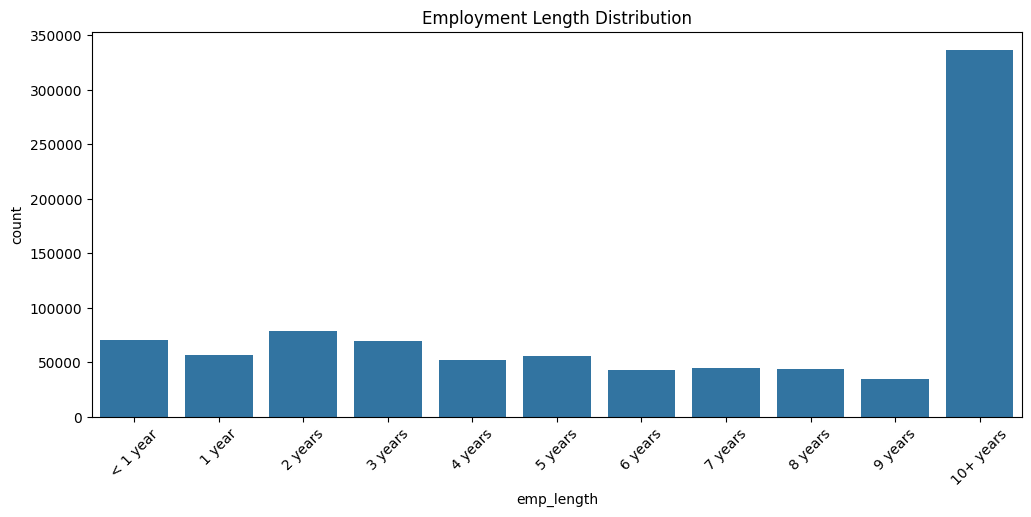

In [79]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=data,
    x="emp_length",
    order=emp_order
)

plt.title("Employment Length Distribution")

plt.xticks(rotation=45)

plt.show()

borrowers with longer employment histories dominate the portfolio.

###Loan Purpose Distribution
**Hypothesis H13-** Debt Consolidation and Credit Card loans account for the majority of loans.

In [80]:
purpose_dist = (
    data["purpose"]
    .value_counts()
    .head(10)
    .reset_index()
)

purpose_dist.columns = ["Purpose","Loans"]

purpose_dist

,Purpose,Loans
0,debt_consolidation,524214
1,credit_card,206182
2,home_improvement,51829
3,other,42866
4,major_purchase,17277
5,small_business,10377
6,car,8863
7,medical,8540
8,moving,5414
9,vacation,4736


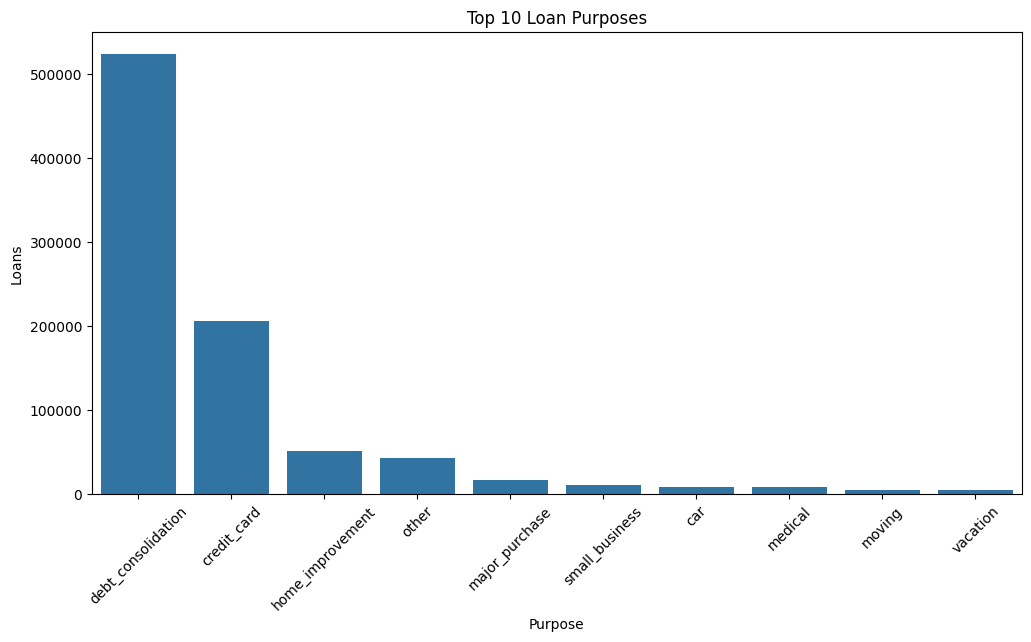

In [81]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=purpose_dist,
    x="Purpose",
    y="Loans"
)

plt.xticks(rotation=45)

plt.title("Top 10 Loan Purposes")

plt.show()

Understanding the most common borrowing purposes helps identify key lending segments and risk concentrations.

###Default Rate by Loan Purpose
**Hypothesis H14-** Debt Consolidation loans exhibit higher default rates than most other purposes.

In [82]:
purpose_default = (
    data.groupby("purpose")["default_flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index()
)

purpose_default.head(15)

,purpose,default_flag
0,educational,13.238771
1,small_business,13.211911
2,wedding,11.291010
3,renewable_energy,9.391304
4,moving,7.850018
5,house,7.715134
6,other,6.849251
7,medical,6.662763
8,vacation,5.701014
9,debt_consolidation,5.264835


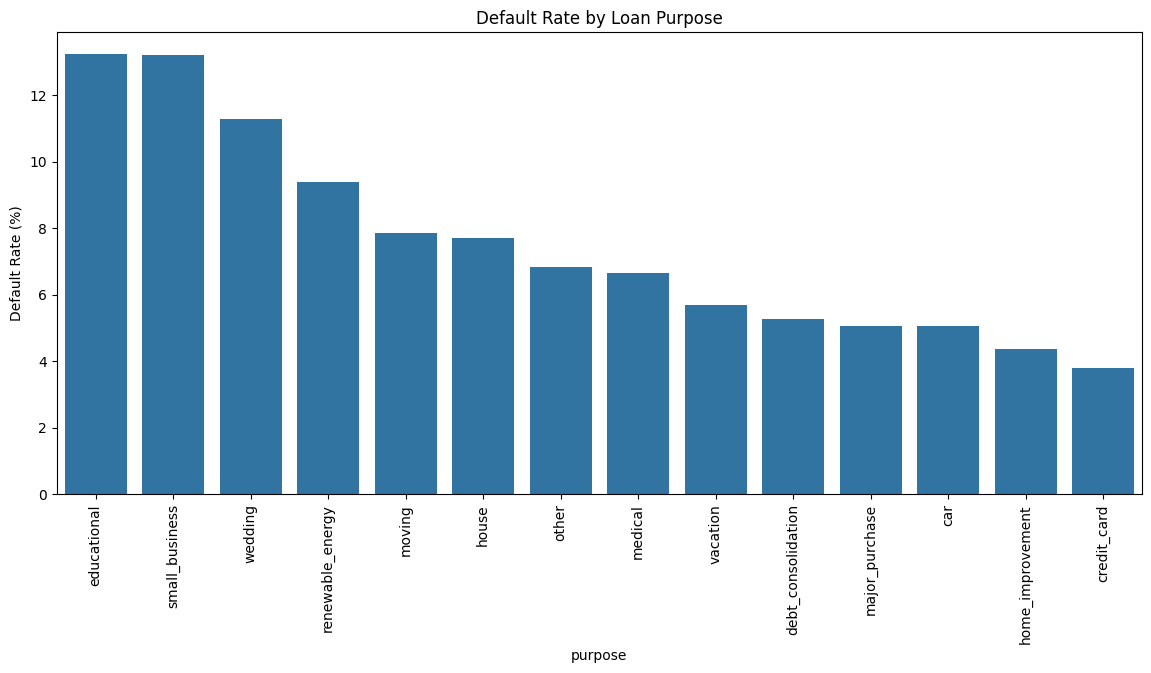

In [83]:
plt.figure(figsize=(14,6))

sns.barplot(
    data=purpose_default,
    x="purpose",
    y="default_flag"
)

plt.xticks(rotation=90)

plt.title("Default Rate by Loan Purpose")

plt.ylabel("Default Rate (%)")

plt.show()

Purposes with consistently high default rates may require:

* Higher interest rates
* Lower approval limits
* Stricter underwriting

###Home Ownership Distribution

In [84]:
ownership = (
    data["home_ownership"]
    .value_counts()
    .reset_index()
)

ownership.columns = ["Home Ownership","Loans"]

ownership

,Home Ownership,Loans
0,MORTGAGE,443550
1,RENT,356100
2,OWN,87469
3,OTHER,182
4,NONE,46
5,ANY,3


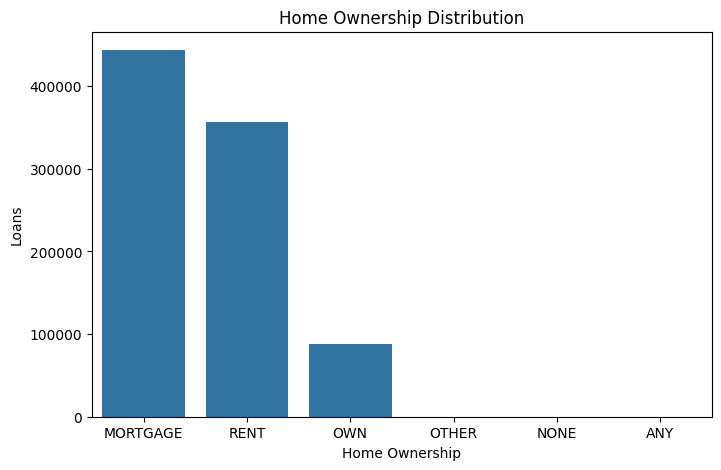

In [85]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=ownership,
    x="Home Ownership",
    y="Loans"
)

plt.title("Home Ownership Distribution")

plt.show()

Housing stability often influences repayment capacity.

###Default Rate by Home Ownership
**Hypothesis H15-** Homeowners default less frequently than renters.

In [86]:
ownership_default = (
    data.groupby("home_ownership")["default_flag"]
    .mean()
    .mul(100)
    .reset_index()
)

ownership_default

,home_ownership,default_flag
0,ANY,0.000000
1,MORTGAGE,4.481569
2,NONE,15.217391
3,OTHER,14.835165
4,OWN,4.601630
5,RENT,5.984555


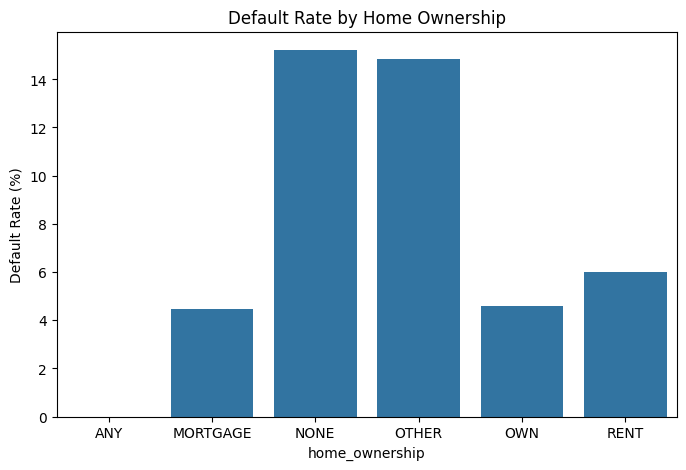

In [87]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=ownership_default,
    x="home_ownership",
    y="default_flag"
)

plt.title("Default Rate by Home Ownership")

plt.ylabel("Default Rate (%)")

plt.show()

Home ownership can act as a proxy for financial stability.

###Revolving Utilization Distribution

How heavily are borrowers using their available credit?



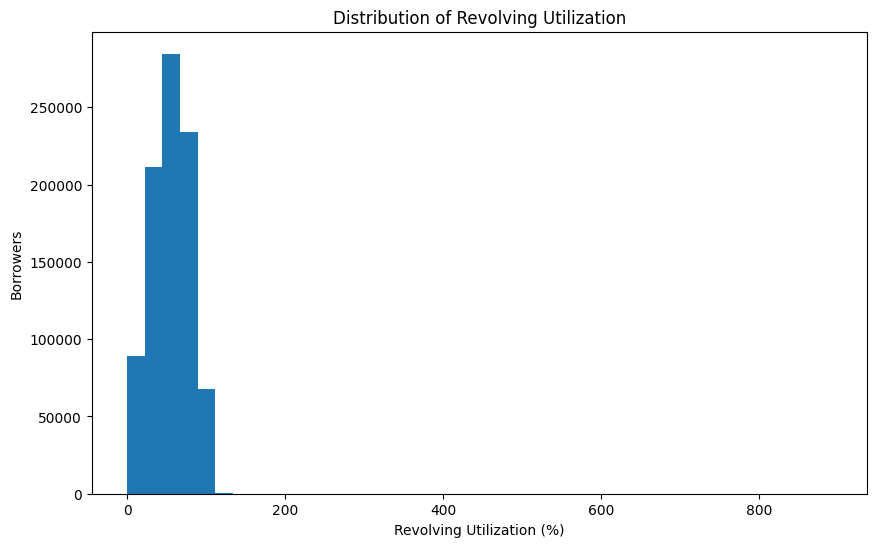

In [88]:
plt.figure(figsize=(10,6))

plt.hist(
    data["revol_util"],
    bins=40
)

plt.title("Distribution of Revolving Utilization")

plt.xlabel("Revolving Utilization (%)")

plt.ylabel("Borrowers")

plt.show()

High utilization often indicates financial stress.

###Revolving Utilization vs Default
**Hypothesis H16-** Borrowers with higher revolving utilization have higher default rates.


In [89]:
#Create Utilization Groups
data["util_group"] = pd.cut(
    data["revol_util"],
    bins=[0,20,40,60,80,100],
    labels=[
        "0-20",
        "20-40",
        "40-60",
        "60-80",
        "80-100"
    ]
)

In [90]:
util_default = (
    data.groupby("util_group", observed=False)["default_flag"]
    .mean()
    .mul(100)
    .reset_index()
)

util_default

,util_group,default_flag
0,0-20,3.654559
1,20-40,3.941457
2,40-60,4.758238
3,60-80,5.737667
4,80-100,6.658665


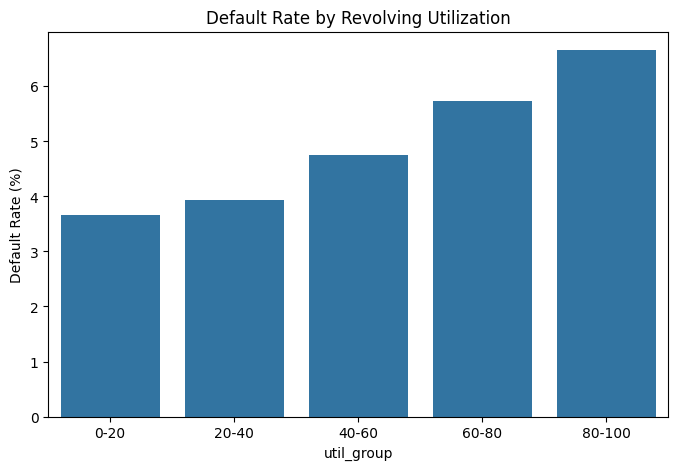

In [91]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=util_default,
    x="util_group",
    y="default_flag"
)

plt.title("Default Rate by Revolving Utilization")

plt.ylabel("Default Rate (%)")

plt.show()

###Installment Distribution

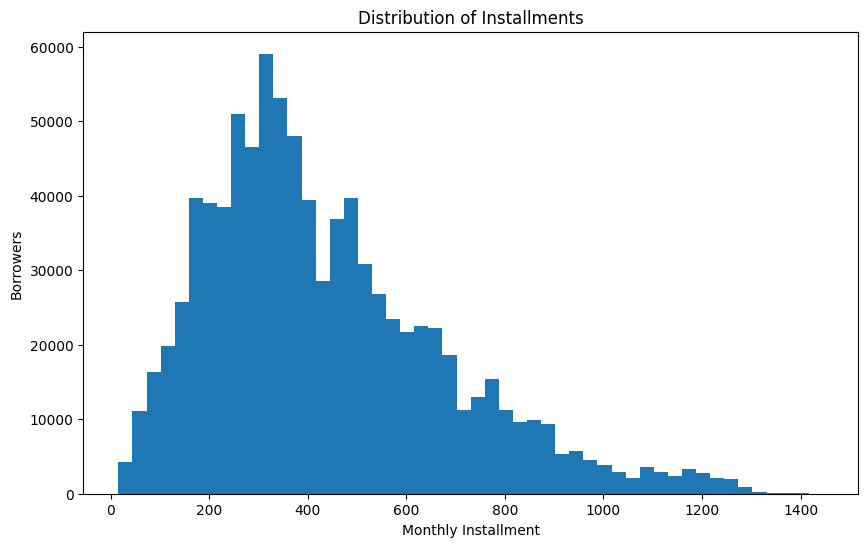

In [92]:
plt.figure(figsize=(10,6))

plt.hist(
    data["installment"],
    bins=50
)

plt.title("Distribution of Installments")

plt.xlabel("Monthly Installment")

plt.ylabel("Borrowers")

plt.show()

###Installment vs Default

**Hypothesis H17-** Higher installments may create repayment pressure.

In [93]:
#create installment group
data["installment_group"] = pd.qcut(
    data["installment"],
    q=4,
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

In [94]:
installment_default = (
    data.groupby("installment_group", observed=False)["default_flag"]
    .mean()
    .mul(100)
    .reset_index()
)

installment_default

,installment_group,default_flag
0,Low,4.931222
1,Medium,4.966556
2,High,5.388008
3,Very High,5.112622


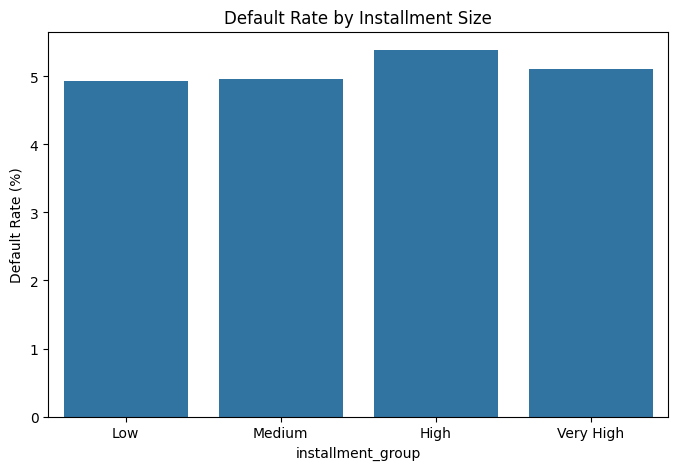

In [95]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=installment_default,
    x="installment_group",
    y="default_flag"
)

plt.title("Default Rate by Installment Size")

plt.ylabel("Default Rate (%)")

plt.show()

Our hypothesis does not hold.

###State-wise Loan Volume

In [96]:
state_loans = (
    data["addr_state"]
    .value_counts()
    .head(15)
    .reset_index()
)

state_loans.columns = ["State","Loans"]

state_loans

,State,Loans
0,CA,129517
1,NY,74077
2,TX,71137
3,FL,60933
4,IL,35476
5,NJ,33253
6,PA,31393
7,OH,29630
8,GA,29084
9,VA,26255


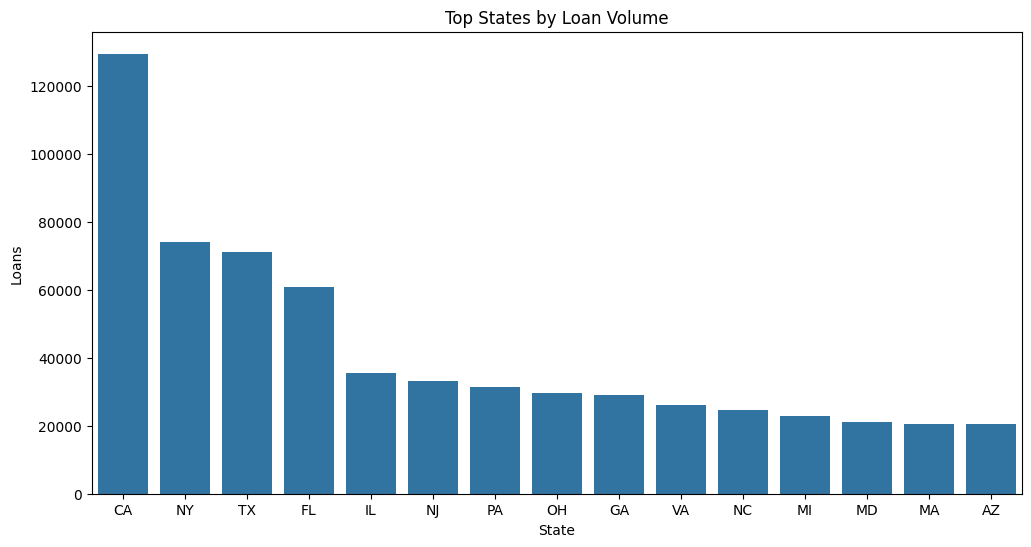

In [97]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=state_loans,
    x="State",
    y="Loans"
)

plt.title("Top States by Loan Volume")

plt.show()

###State-wise Default Rate

In [98]:
state_default = (
    data.groupby("addr_state")["default_flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

state_default

,addr_state,default_flag
0,ID,8.333333
1,IA,7.142857
2,NV,6.453428
3,HI,6.039387
4,AL,5.910714
5,FL,5.783401
6,CA,5.661033
7,UT,5.571520
8,NY,5.567180
9,NJ,5.536343


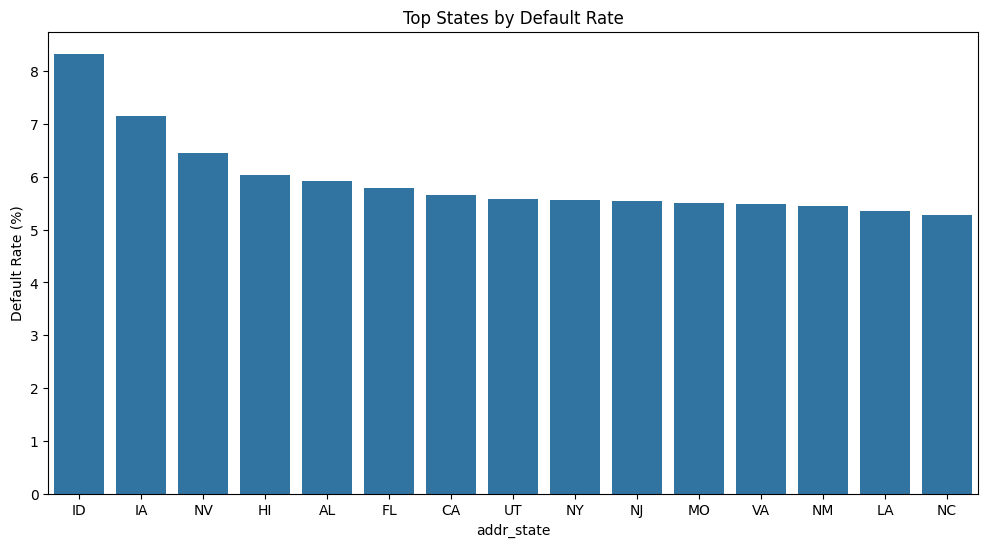

In [99]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=state_default,
    x="addr_state",
    y="default_flag"
)

plt.title("Top States by Default Rate")

plt.ylabel("Default Rate (%)")

plt.show()

###Correlation Heatmap

In [100]:
num_cols = [
    "loan_amnt",
    "funded_amnt",
    "int_rate",
    "installment",
    "annual_inc",
    "dti",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "default_flag"
]

corr = data[num_cols].corr()

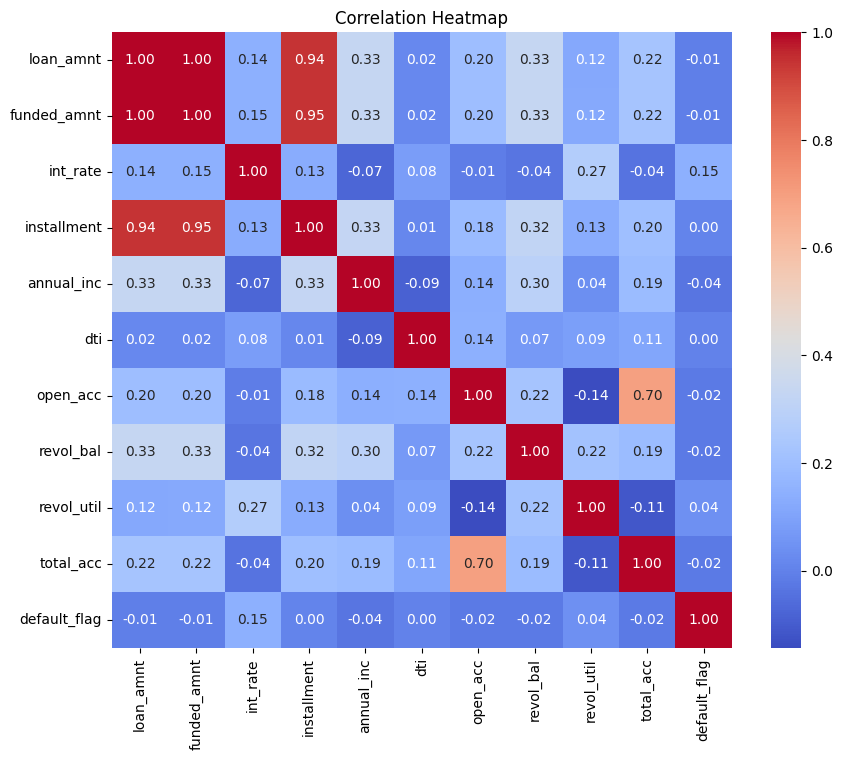

In [101]:
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

* default_flag
* int_rate
* dti

These are likely key risk drivers.

###Boxplot of Annual Income

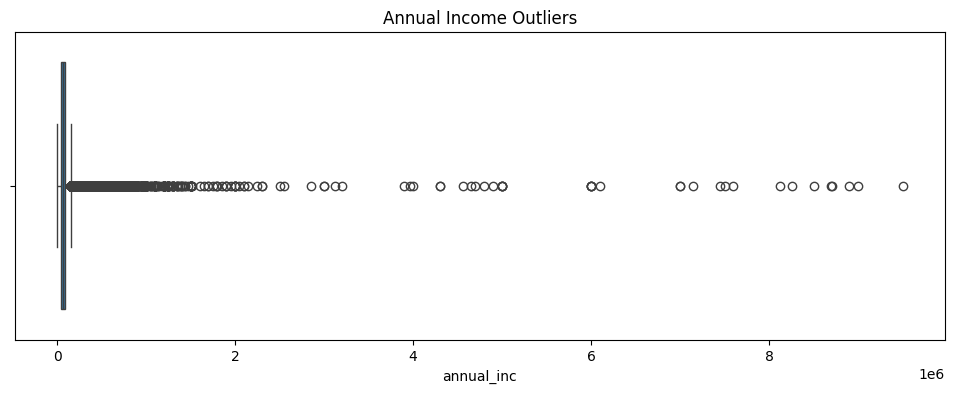

In [102]:
plt.figure(figsize=(12,4))

sns.boxplot(
    x=data["annual_inc"]
)

plt.title("Annual Income Outliers")

plt.show()

###Boxplot of DTI

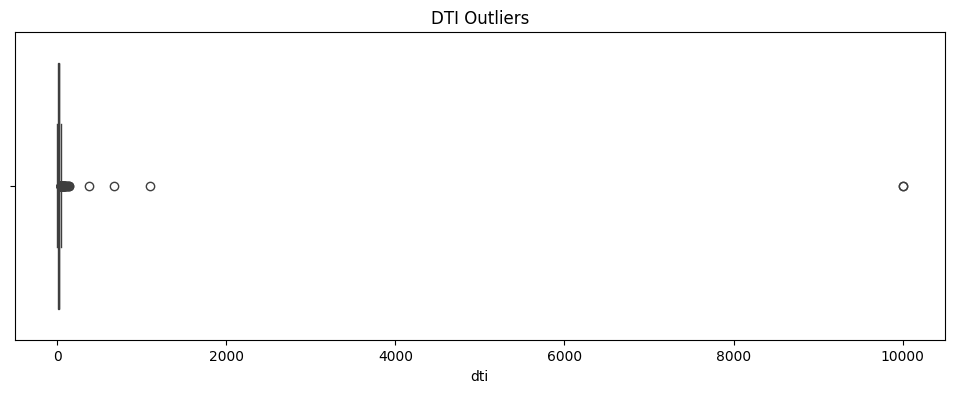

In [103]:
plt.figure(figsize=(12,4))

sns.boxplot(
    x=data["dti"]
)

plt.title("DTI Outliers")

plt.show()

###Boxplot of Revolving Utilization

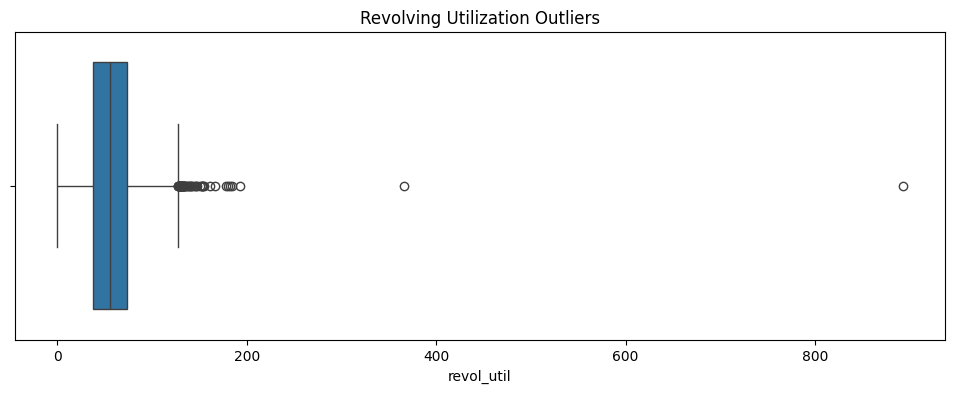

In [104]:
plt.figure(figsize=(12,4))

sns.boxplot(
    x=data["revol_util"]
)

plt.title("Revolving Utilization Outliers")

plt.show()

###Grade vs Interest Rate

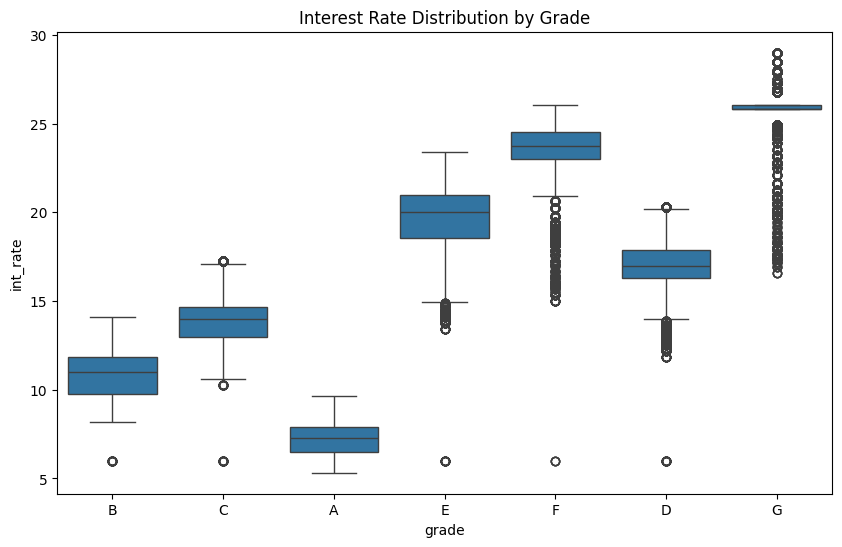

In [105]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=data,
    x="grade",
    y="int_rate"
)

plt.title("Interest Rate Distribution by Grade")

plt.show()

# Hypothesis Testing

In this section, statistical tests are performed to validate whether observed differences in repayment performance across borrower groups are statistically significant. These tests support data-driven business recommendations.

**Hypothesis 1:** Interest Rate vs Default
Business Question

Do defaulted loans have higher interest rates than non-defaulted loans?

**Null Hypothesis (H₀)**

The average interest rate is the same for defaulted and non-defaulted loans.

**Alternative Hypothesis (H₁)**

Defaulted loans have a significantly higher average interest rate.

In [106]:
from scipy.stats import ttest_ind

default = data[data["default_flag"] == 1]["int_rate"]

non_default = data[data["default_flag"] == 0]["int_rate"]

t_stat, p_value = ttest_ind(default, non_default, equal_var=False)

print("T-statistic:", round(t_stat,3))
print("P-value:", p_value)

T-statistic: 140.437
P-value: 0.0


In [108]:
if p_value < 0.05:
    print("Reject Null Hypothesis")
else:
    print("Fail to Reject Null Hypothesis")

Reject Null Hypothesis


higher interest rates are significantly associated with loan defaults.

**Hypothesis 2: Annual Income vs Default**

**H₀**

Average income is the same for defaulted and non-defaulted borrowers.

**H₁**

Defaulted borrowers have different average income.

In [111]:
from scipy.stats import ttest_ind

default_income = data[data["default_flag"] == 1]["annual_inc"]
non_default_income = data[data["default_flag"] == 0]["annual_inc"]

t_stat, p_value = ttest_ind(
    default_income,
    non_default_income,
    equal_var=False
)

print("T-statistic:", round(t_stat,3))
print("P-value:", p_value)

if p_value < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Annual income has a statistically significant relationship with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Annual income does not show a statistically significant relationship with loan default.")

T-statistic: -37.816
P-value: 1.033298914566653e-308

Decision: Reject the Null Hypothesis
Conclusion: Annual income has a statistically significant relationship with loan default.


Since the p-value is less than 0.05, the null hypothesis is rejected. There is sufficient statistical evidence to conclude that annual income significantly differs between defaulted and non-defaulted borrowers.

**Hypothesis 3: DTI vs Default**


**H₀:** Debt-to-income ratio does not differ between defaulted and non-defaulted borrowers.

**H₁:** Debt-to-income ratio differs significantly between defaulted and non-defaulted borrowers.

In [112]:
default_dti = data[data["default_flag"] == 1]["dti"]
non_default_dti = data[data["default_flag"] == 0]["dti"]

t_stat, p_value = ttest_ind(
    default_dti,
    non_default_dti,
    equal_var=False
)

print("T-statistic:", round(t_stat,3))
print("P-value:", p_value)

if p_value < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Debt-to-Income Ratio significantly influences loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Debt-to-Income Ratio does not significantly influence loan default.")

T-statistic: 6.175
P-value: 6.66797646686438e-10

Decision: Reject the Null Hypothesis
Conclusion: Debt-to-Income Ratio significantly influences loan default.


Since the p-value is below 0.05, the null hypothesis is rejected. Borrowers with different debt-to-income ratios exhibit significantly different default behaviour.

**Hypothesis 4: Loan Term vs Default**


**H₀:** Loan term and loan default are independent.

**H₁:** Loan term and loan default are associated.

In [113]:
from scipy.stats import chi2_contingency

contingency = pd.crosstab(data["term"], data["default_flag"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square Statistic:", round(chi2,3))
print("P-value:", p)

if p < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Loan term has a significant association with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Loan term does not have a significant association with loan default.")

Chi-square Statistic: 742.439
P-value: 1.768047863037682e-163

Decision: Reject the Null Hypothesis
Conclusion: Loan term has a significant association with loan default.


The p-value is less than 0.05; therefore, loan term is significantly associated with loan default. Longer repayment terms may increase credit risk.

**Hypothesis 5: Verification Status vs Default**


**H₀:** Verification status and loan default are independent.

**H₁:** Verification status and loan default are associated.

In [114]:
table = pd.crosstab(
    data["verification_status"],
    data["default_flag"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", round(chi2,3))
print("P-value:", p)

if p < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Verification status has a significant association with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Verification status does not have a significant association with loan default.")

Chi-square Statistic: 2149.995
P-value: 0.0

Decision: Reject the Null Hypothesis
Conclusion: Verification status has a significant association with loan default.


Income verification significantly influences loan repayment behaviour, suggesting that verification policies improve credit quality.

**Hypothesis 6: Home Ownership vs Default**

**H₀:** Home ownership and loan default are independent.

**H₁:** Home ownership and loan default are associated.

In [115]:
table = pd.crosstab(
    data["home_ownership"],
    data["default_flag"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", round(chi2,3))
print("P-value:", p)

if p < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Home ownership has a significant association with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Home ownership does not have a significant association with loan default.")

Chi-square Statistic: 1016.746
P-value: 1.4234236415464042e-217

Decision: Reject the Null Hypothesis
Conclusion: Home ownership has a significant association with loan default.


Home ownership status significantly affects default behaviour and may be considered in credit risk evaluation.

**Hypothesis 7: Loan Purpose vs Default**

**H₀:** Loan purpose and loan default are independent.

**H₁:** Loan purpose and loan default are associated.

In [116]:
table = pd.crosstab(
    data["purpose"],
    data["default_flag"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", round(chi2,3))
print("P-value:", p)

if p < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Loan purpose has a significant association with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Loan purpose does not have a significant association with loan default.")

Chi-square Statistic: 2941.639
P-value: 0.0

Decision: Reject the Null Hypothesis
Conclusion: Loan purpose has a significant association with loan default.


The purpose for which a loan is taken significantly affects repayment performance. High-risk loan purposes should receive additional scrutiny.

**Hypothesis 8: Grade vs Default**

**H₀:** Loan grade and loan default are independent.

**H₁:** Loan grade and loan default are associated.

In [117]:
table = pd.crosstab(
    data["grade"],
    data["default_flag"]
)

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square Statistic:", round(chi2,3))
print("P-value:", p)

if p < 0.05:
    print("\nDecision: Reject the Null Hypothesis")
    print("Conclusion: Loan grade has a significant association with loan default.")
else:
    print("\nDecision: Fail to Reject the Null Hypothesis")
    print("Conclusion: Loan grade does not have a significant association with loan default.")

Chi-square Statistic: 11875.189
P-value: 0.0

Decision: Reject the Null Hypothesis
Conclusion: Loan grade has a significant association with loan default.


Loan grade is statistically associated with default behaviour. Lower-grade loans carry significantly higher credit risk and should continue to receive higher risk-based pricing and stricter underwriting.

# Key Findings

1. Loan grade strongly influences repayment performance.
2. Lower grades exhibit substantially higher default rates.
3. Higher interest rates are associated with higher default rates.
4. Borrowers with higher DTI are more likely to default.
5. Higher-income borrowers demonstrate better repayment behaviour.
6. Long-term loans (60 months) show greater default risk.
7. Debt consolidation loans form the largest borrowing segment.
8. Income verification improves credit quality.
9. Higher revolving credit utilization is associated with greater default risk.
10. The Completed Loan Repayment Rate exceeds the Overall Loan Repayment Rate because active loans are still in the repayment cycle.

# Recommendations

1. Strengthen underwriting standards for Grades E, F, and G.
2. Closely monitor borrowers with high Debt-to-Income ratios.
3. Apply stricter approval criteria for 60-month loans.
4. Encourage income verification during the application process.
5. Use borrower income and revolving utilization as key risk indicators.
6. Consider differentiated pricing for high-risk loan purposes.
7. Develop early warning systems for borrowers with multiple high-risk characteristics.
8. Regularly monitor Loan Repayment Rate using both Overall and Completed LRR.

# Conclusion

The analysis identified several borrower and loan characteristics that significantly influence repayment performance. Loan grade, interest rate, debt-to-income ratio, annual income, loan term, and verification status all contribute to default risk. By incorporating these factors into underwriting and risk pricing strategies, UCUCI Bank can improve its Loan Repayment Rate, reduce credit losses, and support sustainable growth of its lending portfolio.